* use new notation of $\bar{N}$, and things, and define new command... in the paper $\boxed \checkmark$
* truncate the $z(t)$ when two boundary hits $\boxed \checkmark$
* do comparasion of analytical solution v.s. numerical solution of $z(t)$, do $t_{\rm eq}$ v.s. $z_0$

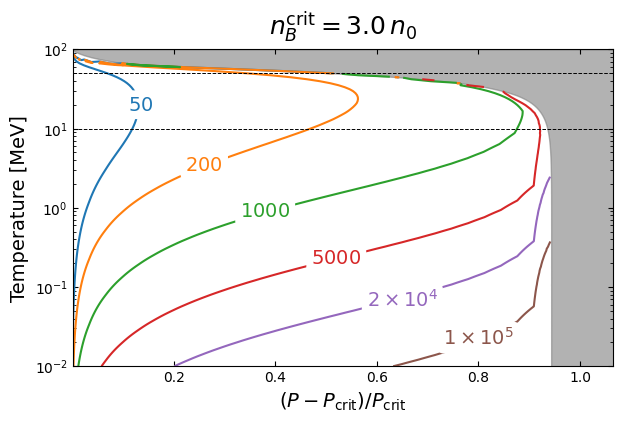

In [14]:
# core3_plot_min_fixed.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from matplotlib.colors import ListedColormap

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
nc3 = 3.0 * n0
al = 0.6  # shading alpha
EPS = 0.005 * 6.1e8 / 3
Pcrit = 6.1e8

# ------------------ same TT definition as used in solver ------------------
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=160)

# Δn grid
N = 30

# ------------------ load precomputed data ------------------
V3 = np.load("v_P_crit_3n0_TTpiece__v1.npy")
DelP_cut3, T_cut3 = np.load("Shade_P_crit_3n0_TTpiece__v1.npy", allow_pickle=True)

# ---- robust interp: sort + unique T_cut3 to avoid NaNs / bad extrapolation ----
T_cut3 = np.asarray(T_cut3, dtype=float)
DelP_cut3 = np.asarray(DelP_cut3, dtype=float)

m = np.isfinite(T_cut3) & np.isfinite(DelP_cut3)
T_cut3, DelP_cut3 = T_cut3[m], DelP_cut3[m]

order = np.argsort(T_cut3)
T_cut3, DelP_cut3 = T_cut3[order], DelP_cut3[order]

Tuniq, idx = np.unique(T_cut3, return_index=True)
DelPuniq = DelP_cut3[idx]

Cut3 = interp1d(Tuniq, DelPuniq, kind="linear", fill_value="extrapolate", bounds_error=False)

# ------------------ build grids ------------------
t = np.linspace(0.0, 1.0, N)
Dlo = 5e5
Dhi = 1e9
Dmax = np.minimum(Dhi, Cut3(TT) - EPS)
Dmax = np.maximum(Dmax, Dlo)

D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

# ------------------ contour levels ------------------
levels = [50, 200, 1000, 5000, 20000, 100000]

# ------------------ bright palette + fixed level colors ------------------
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")

def pick(i):
    return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(levels)}

# ------------------ plot ------------------
fig, ax = plt.subplots(figsize=(6.2, 4.2))  # slightly larger helps labels not get clipped

# axis scales/limits FIRST (helps fill/contour clipping behave predictably)
ax.set_xscale("linear")
ax.set_yscale("log")
xmin = 5e5 / Pcrit
xmax = 6.5e8 / Pcrit
ax.set_xlim(xmin, xmax)
ax.set_ylim(0.01, 100)

# ---- grey shaded region (robust) ----
Dcut = Cut3(TT) / Pcrit
mask = np.isfinite(Dcut)
# clip Dcut into plotting window to avoid weird fill artifacts
Dcut_clip = np.clip(Dcut, xmin, xmax)

ax.fill_betweenx(
    TT[mask],
    Dcut_clip[mask],
    xmax,                  # shade to the right edge of the plot window
    color="grey",
    alpha=al,
    zorder=0
)

# ---- contours ----
cs = ax.contour(
    D_grid / Pcrit, T_grid, V3,
    levels=levels,
    colors=[LEVEL_COLOR[l] for l in levels],
    linewidths=1.5,
    zorder=2
)

# ------------------ manual boxed labels using ax.text ------------------
boxkw = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=1)

ax.text(0.135, 20.0, r"$\mathrm{50}$",        color=LEVEL_COLOR[50],     fontsize=14,
        ha="center", va="center", bbox=boxkw, zorder=5)
ax.text(0.26,  3.5,  r"$\mathrm{200}$",       color=LEVEL_COLOR[200],    fontsize=14,
        ha="center", va="center", bbox=boxkw, zorder=5)
ax.text(0.38,  0.9,  r"$\mathrm{1000}$",      color=LEVEL_COLOR[1000],   fontsize=14,
        ha="center", va="center", bbox=boxkw, zorder=5)
ax.text(0.52,  0.23, r"$\mathrm{5000}$",      color=LEVEL_COLOR[5000],   fontsize=14,
        ha="center", va="center", bbox=boxkw, zorder=5)
ax.text(0.65,  0.07, r"$\mathrm{2\times10^4}$", color=LEVEL_COLOR[20000], fontsize=14,
        ha="center", va="center", bbox=boxkw, zorder=5)
ax.text(0.80,  0.023, r"$\mathrm{1}\times10^{5}$", color=LEVEL_COLOR[100000], fontsize=14,
        ha="center", va="center", bbox=boxkw, zorder=5)

# ------------------ axes styling ------------------
ax.set_xlabel(r"$(P - P_{\rm crit})/P_{\rm crit}$", fontsize=14)
ax.set_ylabel("Temperature [MeV]", fontsize=14)
ax.set_title(r"$n_B^{\rm crit} = 3.0\,n_0$", fontsize=18, pad=10)
ax.tick_params(which="both", direction="in", top=True, right=True)

# guide lines
xx = np.linspace(xmin, xmax, 200)
ax.plot(xx, 10*np.ones_like(xx), "k--", lw=0.7, zorder=3)
ax.plot(xx, 50*np.ones_like(xx), "k--", lw=0.7, zorder=3)

# ---- layout: use ONE method + tight bbox for saving ----
fig.tight_layout(pad=0.6)

out = "3n0_P_single_pannel.pdf"
fig.savefig(out, bbox_inches="tight", pad_inches=0.02)
plt.show()

# $z_0(t_{\rm eq})$ plot

In [1]:
from tqdm import tqdm
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFpressurePNM, _set_couplings, RMFsolvePNM, RMFsolvePNM_mu
from RMFsolver.phase_velocity import P_f, vNtoQ_nc, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

param = para.paraQMCRMF3
NM_type = "PNM"
m_s = 0

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")


def PNM_n(nB, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")

In [80]:
T = 15
n_crit0 = 3*n0
dP_over_dr = 2e8 # MeV^4/km

z0_list = np.logspace(-3, 0, 30) # from 1m to 1km

### analytical

$$
t_{\rm eq} = \dfrac{2 z_0^{1/2}}{C}
$$

In [5]:
def C_factor_dP_dr(T, n_crit0, dP_over_dr):
    '''
    Computes the C factor for vNtoQ = C * sqrt(z)

    Parameters:
    - T          : temperature [MeV]
    - n_crit0    : critical density of NM in [MeV^3] at T=0
    - dP_over_dr : in units of MeV^4/km

    Returns:
    - C        : in units of [km]^1/2 * s^-1
    '''

    P_crit = PNM_n(n_crit0, T)
    muB_crit = fsolve(lambda x: PNM(x, T) - P_crit, 1000)[0]
    B_SQM = fsolve(lambda x: PQM(muB_crit, 0, x, T) - P_crit, 100)[0]
    muQ = muB_crit/3
    
    alpha_s = 0.3
    g_s = np.sqrt(4 * np.pi * alpha_s)
    
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    gammaQ = 1/tauQ
    qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h = 1.81317
    part1 = h*T**(5/3)/qD**(2/3)
    part2 = np.pi**3 * T**2 / (12*qD)
    DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
    
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_crit, Mu, B_SQM, T, m_s)
    
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    dPNM_dmuB = Derivative(lambda x: PNM(x, T), n=1)
    
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_crit)
    nB_N = dPNM_dmuB(muB_crit)
    nK_Q = dPQM_dmuK(0)
    aN = (nB_N - nK_Q) / nB_Q
    
    dPQM_dmuB_crit = dPQM_dmuB(muB_crit)
    dPNM_dmuB_crit = dPNM_dmuB(muB_crit)
    
    dP_over_dr *= const.MeV_fm / 1e18

    C = (1/aN) * np.sqrt(DQ * etaQ * gammaQ * 2 * chiK_Q/ nB_Q) * np.sqrt(np.abs(dP_over_dr) * ((1/dPNM_dmuB_crit) - (1/dPQM_dmuB_crit)))

    return 2.137e13 * C

In [81]:
C_const = C_factor_dP_dr(T, n_crit0, dP_over_dr)
print(C_const)
teq_ana_list = np.array([2*np.sqrt(z0_list[i])/C_const for i in range(len(z0_list))])

0.05623428426860758


### numerical

In [82]:
from RMFsolver.phase_velocity import z_time_evolution2
from tqdm import tqdm

t_num = []
z_num = []

time_up = 50

for z0tmp in tqdm(z0_list):
    tt, zz = z_time_evolution2(
        dP_over_dr = 2e8,
        n_crit = 3*n0,
        T = T, 
        z0 = z0tmp,
        Interp1d_Num = 10,
        t_up = time_up,
    )

    t_num.append(tt)
    z_num.append(zz)


00%|█████████████████████████████████████████████████████████████████████████| 30/30 [29:21<00:00, 58.72s/it]

In [83]:
import numpy as np

def teq_func(t, z):
    """
    Return (idx, t[idx]) where z first crosses below 0.
    This uses your observation that numerical solution briefly overshoots z<0
    and then returns to ~0. No shifting by z.min().

    If there is no negative crossing, returns (None, None).
    """
    t = np.asarray(t, dtype=float)
    z = np.asarray(z, dtype=float)
    if t.ndim != 1 or z.ndim != 1 or t.size != z.size:
        raise ValueError("t and z must be 1D arrays of the same length")

    # first index where z becomes negative
    neg = np.where(z < 0.0)[0]
    if neg.size == 0:
        return None, None
    idx = int(neg[0])
    return idx, float(t[idx])

In [84]:
teq_num_list = []
teq_idx = []

for i in range(len(z0_list)):
    teqidx, teqtmp = teq_func(t_num[i], z_num[i])
    teq_num_list.append(teqtmp)
    teq_idx.append(teqidx)

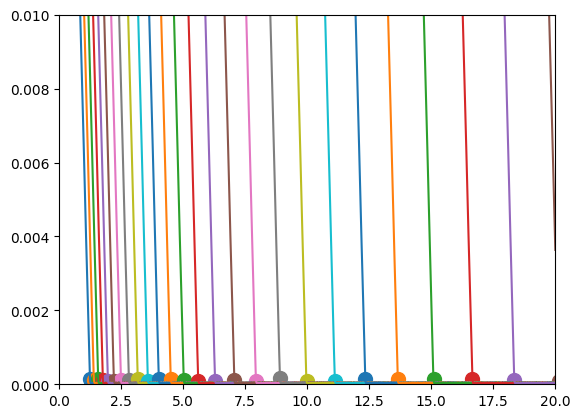

In [85]:
for i in range(len(z0_list)):
    plt.plot(t_num[i], np.sqrt(z_num[i] - np.array(z_num[i]).min()))
    plt.scatter(t_num[i][teq_idx[i]], np.sqrt(z_num[i][teq_idx[i]] - np.array(z_num[i]).min()), s = 100)
    plt.ylim(0, 0.01)
    plt.xlim(0, 20)

### Compare

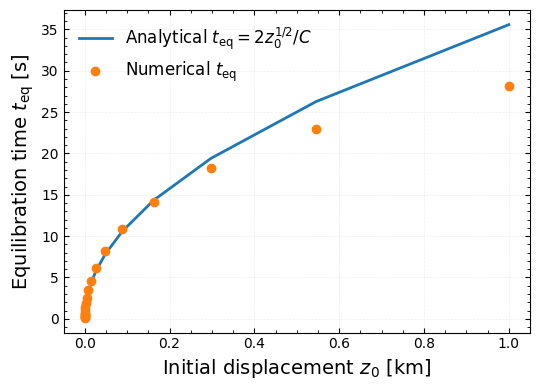

In [72]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5.5, 4))

# analytical result
ax.plot(
    z0_list, teq_ana_list,
    lw=2.0,
    color="tab:blue",
    label=r"Analytical $t_{\rm eq} = 2z_0^{1/2}/C$"
)

# numerical result
ax.plot(
    z0_list, teq_num_list,
    marker="o",
    ms=6,
    lw=0,
    color="tab:orange",
    label=r"Numerical $t_{\rm eq}$"
)

# axes labels
ax.set_xlabel(r"Initial displacement $z_0$ [km]", fontsize=14)
ax.set_ylabel(r"Equilibration time $t_{\rm eq}$ [s]", fontsize=14)

# ticks & style
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()

# legend
ax.legend(frameon=False, fontsize=12)

# optional grid (very light, PRL-friendly)
ax.grid(alpha=0.2, linestyle="--", linewidth=0.5)

plt.tight_layout()
plt.show()

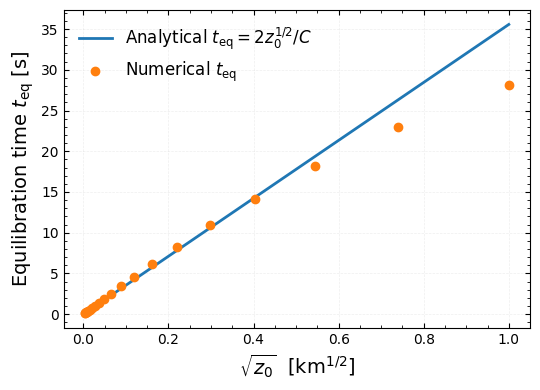

In [74]:
import numpy as np
import matplotlib.pyplot as plt

# transform x-axis
x_sqrt = np.sqrt(z0_list)

fig, ax = plt.subplots(figsize=(5.5, 4))

# analytical result
ax.plot(
    x_sqrt, teq_ana_list,
    lw=2.0,
    color="tab:blue",
    label=r"Analytical $t_{\rm eq} = 2z_0^{1/2}/C$"
)

# numerical result
ax.plot(
    x_sqrt, teq_num_list,
    marker="o",
    ms=6,
    lw=0,
    color="tab:orange",
    label=r"Numerical $t_{\rm eq}$"
)

# labels
ax.set_xlabel(r"$\sqrt{z_0}$  [$\mathrm{km}^{1/2}$]", fontsize=14)
ax.set_ylabel(r"Equilibration time $t_{\rm eq}$ [s]", fontsize=14)

# styling
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()
ax.legend(frameon=False, fontsize=12)

# subtle grid (optional, PRL-friendly)
ax.grid(alpha=0.2, linestyle="--", linewidth=0.5)

plt.tight_layout()
plt.show()

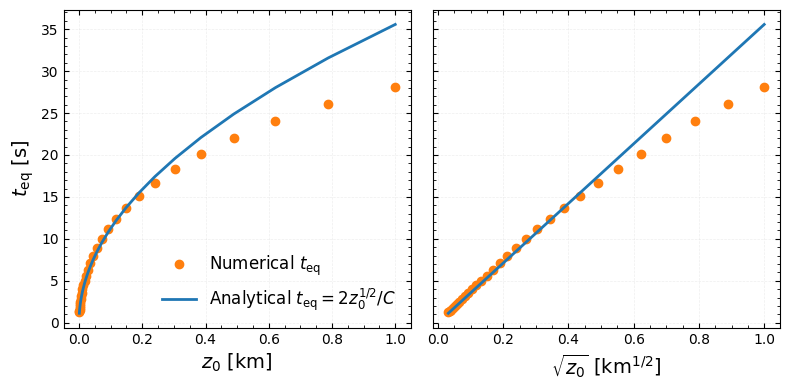

In [87]:
import numpy as np
import matplotlib.pyplot as plt

z0 = np.asarray(z0_list)
x_sqrt = np.sqrt(z0)

fig, axs = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

# =========================
# Left panel: x = z0
# =========================

axs[0].plot(
    z0, teq_num_list,
    marker="o",
    ms=6,
    lw=0,
    color="tab:orange",
    label=r"Numerical $t_{\rm eq}$"
)

axs[0].plot(
    z0, teq_ana_list,
    lw=2.0,
    color="tab:blue",
    label=r"Analytical $t_{\rm eq} = 2z_0^{1/2}/C$"
)

axs[0].set_xlabel(r"$z_0\ \mathrm{[km]}$", fontsize=14)
axs[0].set_ylabel(r"$t_{\rm eq}\ \mathrm{[s]}$", fontsize=14)
axs[0].legend(frameon=False, fontsize=12)
axs[0].tick_params(which="both", direction="in", top=True, right=True)
axs[0].minorticks_on()
axs[0].grid(alpha=0.2, linestyle="--", linewidth=0.5)

# =========================
# Right panel: x = sqrt(z0)
# =========================

axs[1].plot(
    x_sqrt, teq_num_list,
    marker="o",
    ms=6,
    lw=0,
    color="tab:orange",
)

axs[1].plot(
    x_sqrt, teq_ana_list,
    lw=2.0,
    color="tab:blue",
)

axs[1].set_xlabel(r"$\sqrt{z_0}\ \mathrm{[km^{1/2}]}$", fontsize=14)
axs[1].tick_params(which="both", direction="in", top=True, right=True)
axs[1].minorticks_on()
axs[1].grid(alpha=0.2, linestyle="--", linewidth=0.5)

# =========================
# Layout
# =========================
plt.tight_layout()
plt.savefig("teq_z0-2.pdf")
plt.show()

In [4]:
from RMFsolver.phase_velocity import _vNtoQ_formula, _vNtoQ_num

_vNtoQ_formula(T=1, aQstar=0.5, aN=0.8, muQ=300), _vNtoQ_num(T=1, aQstar=0.5, aN=0.8, muQ=300)

(np.float64(379.9751287686793), 30.0)

In [8]:
import numpy as np

T = 5
aQstar = 0.5
aN = 0.8
muQ = 300

# --- microphysics ---
alpha_s = 0.3
g_s   = np.sqrt(4*np.pi*alpha_s)
etaQ  = (9*np.pi**2 * T**2) / muQ**2
tauQ  = 1.98e12 * ((300.0 / muQ)**5)

qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h     = 1.81317
part1 = h * T**(5/3) / qD**(2/3)
part2 = (np.pi**3 * T**2) / (12.0 * qD)
DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

DQ, 1/tauQ, np.sqrt(DQ/tauQ)*3e8

(np.float64(1.4593151055671478),
 5.050505050505051e-13,
 np.float64(257.5509751457111))